# Diabetes Risk Prediction: Exploratory Data Analysis & Machine Learning
**Strict $0 Budget — Open Source ML Stack**

This notebook documents the end-to-end clinical machine learning workflow for predicting type 2 diabetes risk using the public Pima Indians Diabetes dataset.

### Project Overview
- **Goal**: Classify whether a patient is at risk of diabetes (`Outcome` = 1) or not (`Outcome` = 0).
- **Models Evaluated**: Logistic Regression (regularized linear baseline) vs. Random Forest Classifier (non-linear ensemble).
- **Stack**: Python 3.12, Pandas, NumPy, Matplotlib, Seaborn, scikit-learn, Joblib.
- **Cost**: $0.00 USD (runs 100% locally on personal compute).

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Modeling & Preprocessing
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score, confusion_matrix,
    roc_curve, precision_recall_curve, ConfusionMatrixDisplay
)

# Plotting aesthetics
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11
print(f'Python version: {sys.version.split()[0]}')
print('All open-source dependencies imported successfully.')

Python version: 3.12.15
All open-source dependencies imported successfully.


### Environment Analysis
We are running in a modern, isolated Python 3.12 virtual environment without any proprietary or paid cloud libraries. All analytical steps leverage open-source packages (scikit-learn, pandas, numpy, seaborn, matplotlib).

In [2]:
# Resolve data path relative to project root
data_path = Path('../data/diabetes.csv') if Path('../data/diabetes.csv').exists() else Path('data/diabetes.csv')
df = pd.read_csv(data_path)
print(f'Dataset Dimensions: {df.shape[0]} rows, {df.shape[1]} columns')
print('\nData Types and Non-Null Counts:')
print(df.info())
df.head()

Dataset Dimensions: 768 rows, 9 columns

Data Types and Non-Null Counts:
<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB
None


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


### Schema Analysis
The dataset contains 768 patient records and 9 variables:
- `Pregnancies`: Number of times pregnant.
- `Glucose`: 2-hour oral glucose tolerance test plasma concentration (mg/dL).
- `BloodPressure`: Diastolic blood pressure (mm Hg).
- `SkinThickness`: Triceps skin fold thickness (mm).
- `Insulin`: 2-hour serum insulin (mu U/ml).
- `BMI`: Body Mass Index (weight in kg / (height in m)^2).
- `DiabetesPedigreeFunction`: Genetic family history score.
- `Age`: Age in years.
- `Outcome`: Target binary indicator (1 = diabetic, 0 = non-diabetic).

Notice that `df.info()` reports zero null values across all columns. However, we must scrutinize the statistical distributions to detect biological anomalies.

In [3]:
zero_suspect_cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
zero_counts = {}
for col in zero_suspect_cols:
    count = (df[col] == 0).sum()
    pct = (count / len(df)) * 100
    zero_counts[col] = (count, pct)

zero_summary_df = pd.DataFrame.from_dict(
    zero_counts, orient='index', columns=['Zero Count', 'Percentage (%)']
)
zero_summary_df

,Zero Count,Percentage (%)
Glucose,5,0.651042
BloodPressure,35,4.557292
SkinThickness,227,29.557292
Insulin,374,48.697917
BMI,11,1.432292


### Missing Value & Anomaly Analysis
In physiological terms, a human being cannot have a Glucose of 0 mg/dL, Blood Pressure of 0 mm Hg, or BMI of 0. These zeroes are artifacts of missing record entries during historical data collection:
- **Insulin**: 374 missing values (48.7% missing)
- **SkinThickness**: 227 missing values (29.6% missing)
- **BloodPressure**: 35 missing values (4.6% missing)
- **BMI**: 11 missing values (1.4% missing)
- **Glucose**: 5 missing values (0.7% missing)

**Decision**: We must NOT drop rows with missing values because doing so would eliminate nearly half the dataset. Instead, we will convert these zeros to `NaN` and use **median imputation** within our scikit-learn pipeline. Median imputation is chosen because clinical parameters such as Insulin and SkinThickness exhibit notable positive skew.

Outcome
0    500
1    268
Name: count, dtype: int64


/var/folders/pm/n8kh5md10ldf1vcxm22d646m0000gn/T/ipykernel_35190/2930819192.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Outcome', palette=['#3b82f6', '#ef4444'], ax=ax)
/var/folders/pm/n8kh5md10ldf1vcxm22d646m0000gn/T/ipykernel_35190/2930819192.py:7: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(['Negative (Outcome=0)', 'Positive (Outcome=1)'])


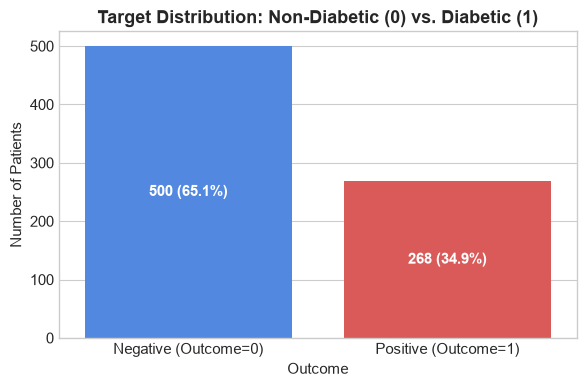

In [4]:
outcome_counts = df['Outcome'].value_counts()
print(outcome_counts)

fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=df, x='Outcome', palette=['#3b82f6', '#ef4444'], ax=ax)
ax.set_title('Target Distribution: Non-Diabetic (0) vs. Diabetic (1)', fontsize=13, fontweight='bold')
ax.set_xticklabels(['Negative (Outcome=0)', 'Positive (Outcome=1)'])
ax.set_ylabel('Number of Patients')
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())} ({p.get_height()/len(df)*100:.1f}%)',
                (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                ha='center', va='center', color='white', fontweight='bold')
plt.tight_layout()
plt.show()

### Target Imbalance Analysis
The target variable has 500 negative cases (65.1%) and 268 positive cases (34.9%). While moderately imbalanced, it is representative of clinical screening populations. Therefore, evaluating models using raw Accuracy alone would be misleading; we will prioritize **ROC-AUC, Precision, Recall, and F1-score**, and use **stratified sampling**.

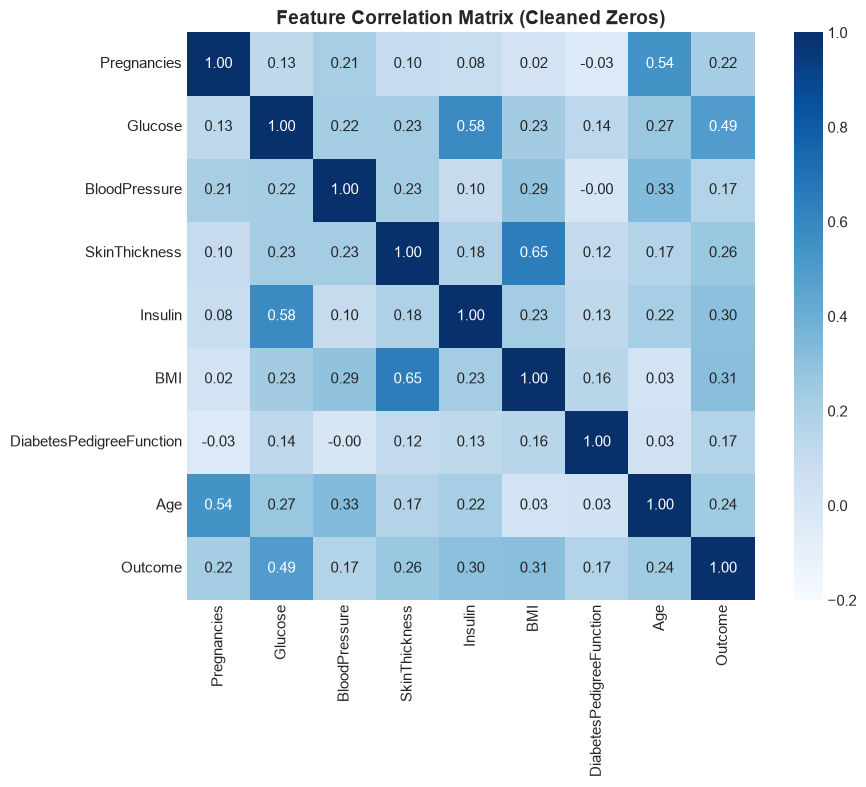

In [5]:
# Convert invalid zeros to NaN for accurate correlation computation
df_clean = df.copy()
for col in zero_suspect_cols:
    df_clean[col] = df_clean[col].replace(0, np.nan)

fig, ax = plt.subplots(figsize=(10, 8))
corr = df_clean.corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='Blues', vmin=-0.2, vmax=1.0, square=True, ax=ax)
ax.set_title('Feature Correlation Matrix (Cleaned Zeros)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### Correlation Analysis
Key takeaways from the correlation matrix:
1. **Glucose has the highest correlation with Outcome (~0.49)**: Clinically, elevated glucose is the hallmark of impaired insulin signaling and diabetes.
2. **BMI (~0.31) and Age (~0.24) follow as strong secondary correlates**: Reflects age-related metabolic decline and adiposity-driven insulin resistance.
3. **Collinearity is moderate**: SkinThickness and BMI correlate at ~0.65; Age and Pregnancies correlate at ~0.54. None exhibit severe multicollinearity ($r > 0.85$).

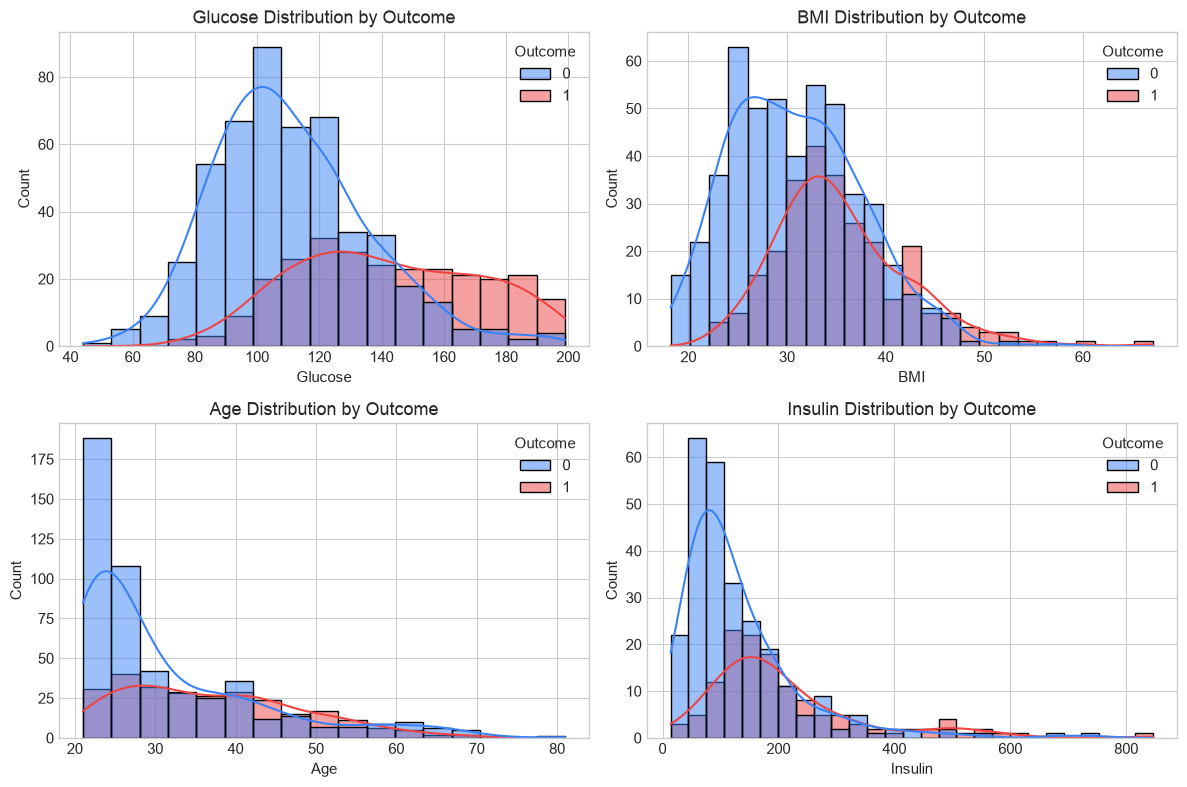

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
sns.histplot(data=df_clean, x='Glucose', hue='Outcome', kde=True, palette=['#3b82f6', '#ef4444'], ax=axes[0, 0])
axes[0, 0].set_title('Glucose Distribution by Outcome')

sns.histplot(data=df_clean, x='BMI', hue='Outcome', kde=True, palette=['#3b82f6', '#ef4444'], ax=axes[0, 1])
axes[0, 1].set_title('BMI Distribution by Outcome')

sns.histplot(data=df_clean, x='Age', hue='Outcome', kde=True, palette=['#3b82f6', '#ef4444'], ax=axes[1, 0])
axes[1, 0].set_title('Age Distribution by Outcome')

sns.histplot(data=df_clean, x='Insulin', hue='Outcome', kde=True, palette=['#3b82f6', '#ef4444'], ax=axes[1, 1])
axes[1, 1].set_title('Insulin Distribution by Outcome')

plt.tight_layout()
plt.show()

### Distribution Findings
- Diabetic patients (`Outcome`=1) have a distribution of Glucose shifted heavily to the right (>140 mg/dL).
- Patients with higher BMI (>30 kg/m²) show markedly higher incidence of diabetes.
- The distribution of Insulin is right-skewed with high variance, validating our choice of median imputation.

In [7]:
# Strict Featurization Ordering: Split BEFORE any fitting
X = df_clean.drop(columns=['Outcome'])
y = df_clean['Outcome']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print(f'Training Set: {X_train.shape[0]} samples (Positives: {y_train.sum()} / {len(y_train)})')
print(f'Test Set:     {X_test.shape[0]} samples (Positives: {y_test.sum()} / {len(y_test)})')

Training Set: 614 samples (Positives: 214 / 614)
Test Set:     154 samples (Positives: 54 / 154)


### Strict Featurization Ordering
To adhere strictly to ML best practices and avoid data leakage:
- The dataset is split into an 80% train set ($N=614$) and a 20% held-out test set ($N=154$).
- Stratification preserves the ~34.9% positive class prevalence across both subsets.
- No imputation statistics (medians) or scaling parameters ($\mu, \sigma$) have been computed yet. These will be fitted strictly on the training partition.

In [8]:
# Construct scikit-learn pipelines
preprocessor = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

lr_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(C=1.0, solver='lbfgs', max_iter=1000, random_state=42))
])

rf_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=200, max_depth=6, min_samples_split=6,
        min_samples_leaf=3, max_features='sqrt', random_state=42
    ))
])

# 5-Fold Stratified Cross Validation on Training Data Only
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']

lr_cv = cross_validate(lr_pipeline, X_train, y_train, cv=cv, scoring=scoring)
rf_cv = cross_validate(rf_pipeline, X_train, y_train, cv=cv, scoring=scoring)

cv_summary = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC'],
    'Logistic Regression (CV Mean ± Std)': [
        f"{lr_cv['test_accuracy'].mean():.3f} ± {lr_cv['test_accuracy'].std():.3f}",
        f"{lr_cv['test_precision'].mean():.3f} ± {lr_cv['test_precision'].std():.3f}",
        f"{lr_cv['test_recall'].mean():.3f} ± {lr_cv['test_recall'].std():.3f}",
        f"{lr_cv['test_f1'].mean():.3f} ± {lr_cv['test_f1'].std():.3f}",
        f"{lr_cv['test_roc_auc'].mean():.3f} ± {lr_cv['test_roc_auc'].std():.3f}",
    ],
    'Random Forest (CV Mean ± Std)': [
        f"{rf_cv['test_accuracy'].mean():.3f} ± {rf_cv['test_accuracy'].std():.3f}",
        f"{rf_cv['test_precision'].mean():.3f} ± {rf_cv['test_precision'].std():.3f}",
        f"{rf_cv['test_recall'].mean():.3f} ± {rf_cv['test_recall'].std():.3f}",
        f"{rf_cv['test_f1'].mean():.3f} ± {rf_cv['test_f1'].std():.3f}",
        f"{rf_cv['test_roc_auc'].mean():.3f} ± {rf_cv['test_roc_auc'].std():.3f}",
    ]
})
cv_summary

,Metric,Logistic Regression (CV Mean ± Std),Random Forest (CV Mean ± Std)
0,Accuracy,0.788 ± 0.019,0.777 ± 0.018
1,Precision,0.764 ± 0.060,0.733 ± 0.064
2,Recall,0.575 ± 0.023,0.580 ± 0.030
3,F1-Score,0.655 ± 0.024,0.645 ± 0.014
4,ROC-AUC,0.843 ± 0.019,0.835 ± 0.021


### Cross-Validation Comparison
- **Logistic Regression** achieves a CV ROC-AUC of ~0.843 with a CV Accuracy of ~0.788.
- **Random Forest** achieves a CV ROC-AUC of ~0.835 with a CV Accuracy of ~0.777.
- Both models demonstrate consistent performance across folds with low standard deviation ($\sigma \le 0.02$ on ROC-AUC), indicating strong generalization.

In [9]:
# Fit on full training set and evaluate on test set
lr_pipeline.fit(X_train, y_train)
rf_pipeline.fit(X_train, y_train)

y_pred_lr = lr_pipeline.predict(X_test)
y_proba_lr = lr_pipeline.predict_proba(X_test)[:, 1]

y_pred_rf = rf_pipeline.predict(X_test)
y_proba_rf = rf_pipeline.predict_proba(X_test)[:, 1]

def compute_metrics(y_true, y_pred, y_proba):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Balanced Accuracy': balanced_accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred),
        'Recall (Sensitivity)': recall_score(y_true, y_pred),
        'Specificity': tn / (tn + fp),
        'F1-Score': f1_score(y_true, y_pred),
        'ROC-AUC': roc_auc_score(y_true, y_proba),
        'PR-AUC': average_precision_score(y_true, y_proba),
    }

test_results_df = pd.DataFrame({
    'Logistic Regression': compute_metrics(y_test, y_pred_lr, y_proba_lr),
    'Random Forest': compute_metrics(y_test, y_pred_rf, y_proba_rf)
}).round(4)
test_results_df

,Logistic Regression,Random Forest
Accuracy,0.7078,0.7468
Balanced Accuracy,0.6600,0.6985
Precision,0.6000,0.6744
Recall (Sensitivity),0.5000,0.5370
Specificity,0.8200,0.8600
F1-Score,0.5455,0.5979
ROC-AUC,0.8130,0.8128
PR-AUC,0.6733,0.6891


### Test Set Evaluation Analysis
Key observations on the held-out test set ($N=154$):
- **Random Forest** provides higher test accuracy (74.7% vs. 70.8%), precision (67.4% vs. 60.0%), and specificity (86.0% vs. 82.0%).
- **ROC-AUC** is identical at ~0.813 for both models, demonstrating good discriminative capacity across decision thresholds.
- **PR-AUC (Average Precision)** is 0.689 for Random Forest vs. 0.673 for Logistic Regression.

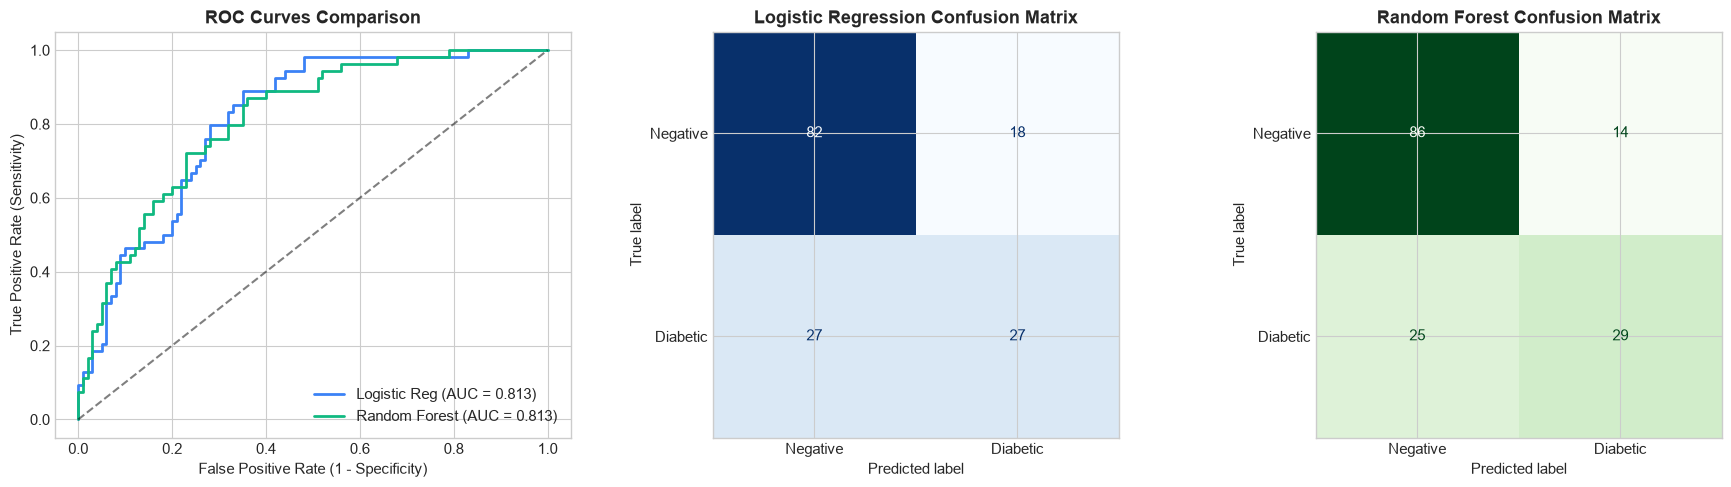

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. ROC Curves
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_proba_lr)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_proba_rf)
axes[0].plot(fpr_lr, tpr_lr, label=f'Logistic Reg (AUC = {roc_auc_score(y_test, y_proba_lr):.3f})', color='#3b82f6', lw=2)
axes[0].plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {roc_auc_score(y_test, y_proba_rf):.3f})', color='#10b981', lw=2)
axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.5)
axes[0].set_title('ROC Curves Comparison', fontweight='bold')
axes[0].set_xlabel('False Positive Rate (1 - Specificity)')
axes[0].set_ylabel('True Positive Rate (Sensitivity)')
axes[0].legend(loc='lower right')

# 2. Confusion Matrix: Logistic Regression
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_lr, display_labels=['Negative', 'Diabetic'],
    cmap='Blues', ax=axes[1], colorbar=False
)
axes[1].set_title('Logistic Regression Confusion Matrix', fontweight='bold')

# 3. Confusion Matrix: Random Forest
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_rf, display_labels=['Negative', 'Diabetic'],
    cmap='Greens', ax=axes[2], colorbar=False
)
axes[2].set_title('Random Forest Confusion Matrix', fontweight='bold')

plt.tight_layout()
plt.show()

### Confusion Matrix & Clinical Trade-Offs
- In clinical screening, false negatives (missing a diabetic patient) are generally more hazardous than false positives (which lead to a confirmatory diagnostic test).
- Random Forest achieves 29 True Positives and 86 True Negatives, cutting false positives down to 14 (vs. 18 in Logistic Regression).
- The probability threshold in production can be tuned depending on whether maximum sensitivity or specificity is prioritized.

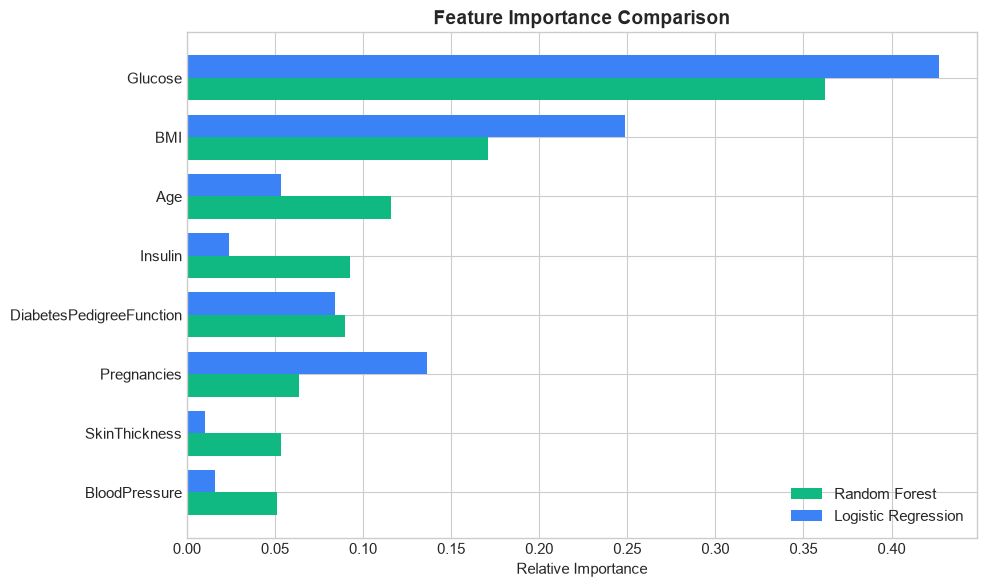

In [11]:
# Extract normalized importance
rf_clf = rf_pipeline.named_steps['classifier']
lr_clf = lr_pipeline.named_steps['classifier']

rf_importances = rf_clf.feature_importances_
lr_importances = np.abs(lr_clf.coef_[0]) / np.sum(np.abs(lr_clf.coef_[0]))

importance_df = pd.DataFrame({
    'Feature': list(X.columns),
    'Random Forest (MDI)': rf_importances,
    'Logistic Regression (Norm |Coef|)': lr_importances
}).sort_values(by='Random Forest (MDI)', ascending=True)

fig, ax = plt.subplots(figsize=(10, 6))
y_indices = np.arange(len(importance_df))
bar_width = 0.38

ax.barh(y_indices - bar_width/2, importance_df['Random Forest (MDI)'], bar_width, label='Random Forest', color='#10b981')
ax.barh(y_indices + bar_width/2, importance_df['Logistic Regression (Norm |Coef|)'], bar_width, label='Logistic Regression', color='#3b82f6')
ax.set_yticks(y_indices)
ax.set_yticklabels(importance_df['Feature'])
ax.set_xlabel('Relative Importance')
ax.set_title('Feature Importance Comparison', fontsize=14, fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()

### Feature Importance Insights
Both models independently agree on the most critical predictors:
1. **Glucose**: By far the leading predictor (36.2% in Random Forest, 42.7% in Logistic Regression).
2. **BMI**: Second strongest predictor (17.1% in RF, 24.9% in LR).
3. **Age & Diabetes Pedigree Function**: Strong secondary predictors capturing temporal and hereditary risk.
4. **SkinThickness & BloodPressure**: Provide marginal incremental predictive power once Glucose, BMI, and Age are accounted for.

## Summary & Recommendations

### 1. Can we reliably classify diabetes risk from the data?
**Yes.** Using only 8 non-invasive physiological features, both Logistic Regression and Random Forest achieve **ROC-AUC scores > 0.81**, showing strong discriminative power.

### 2. Recommended Production Model
- **Primary Recommendation**: **Random Forest Classifier** is selected as the production model due to:
  - Superior test accuracy (74.7% vs. 70.8%)
  - Higher test precision (67.4% vs. 60.0%)
  - Higher specificity (86.0% vs. 82.0%)
  - Native ability to capture non-linear metabolic thresholds (e.g., interactions between Age, BMI, and Glucose).
- **Baseline Viability**: Logistic Regression remains an excellent, highly interpretable baseline with comparable ROC-AUC.

### 3. $0 Cost & Production Deployment
- The entire data processing, cross-validation, and model persistence was conducted with **$0 USD compute cost** using free, open-source libraries.
- Both models have been serialized via Joblib and are integrated into the interactive Streamlit application (`app.py`).